## Problema - Organización y búsqueda de productos en una tienda

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.



In [ ]:
# @title Ingrese datos
nombre_estudiante = "Santiago Camacho Jimenez" # @param {"type":"string"}
carnet = 1000116319 # @param {"type":"integer"}


## 1) Descripción del problema **[1 pts]**


El centro de computo requiere un sistema eficiente para administrar y procesar tareas asincronicas basadas en prioridades numéricas. Las tareas que poseen un valor de prioridad mayor deben ejecutarse antes que las de menor prioridad. Para lograrlo de forma óptima sin utilizar librerías prohibidas como heapq, se implementará una estructura de Max-Heap basada en arreglos tradicionales. El sistema debe permitir registrar tareas, construir el heap, consultar el elemento máximo, extraer la tarea de mayor prioridad, insertar nuevas tareas y ordenar las prioridades mediante el algoritmo HeapSort.

## 2) Requerimientos **[2 pts]**




Requerimientos Funcionales
- El sistema debe permitir al usuario ingresar una cantidad $n$ de tareas, cada una con su código, nombre y prioridad numérica.
- El sistema debe transformar la lista de prioridades original en un Max-Heap válido utilizando los algoritmos manuales MAX-HEAPIFY y BUILD-MAX-HEAP.
- Permitir consultar la tarea con mayor prioridad (raíz del heap) sin eliminarla de la estructura (MAXIMUM).
- Extraer la tarea de mayor prioridad (EXTRACT-MAX), reportarla y reorganizar el heap con MAX-HEAPIFY.
- Permitir ingresar una nueva tarea y ubicarla automáticamente en el heap manteniendo la propiedad de orden (MAX-HEAP).
- Implementar manualmente el algoritmo HeapSort para ordenar las prioridades de menor a mayor sin usar funciones nativas de ordenamiento.  

Requerimientos No Funcionales
- El Max-Heap debe implementarse estrictamente utilizando arreglos (listas de Python).   
- Está prohibido el uso de nodos, punteros basados en clases/objetos para representar el árbol, y la librería heapq.
- Está prohibido el uso de los métodos sort() y sorted() para la sección de HeapSort.
- El código debe estar organizado modularmente en funciones reutilizables y ejecutarse dentro de un Jupyter Notebook.

## 3) Historias de usuario **[2 pts]**


Historia de usuario 1
- Como operador del centro de cómputo quiero registrar un conjunto de tareas y convertirlas automáticamente en un Max-Heap para asegurar que las tareas más críticas queden listas para su procesamiento inmediato.
   - Criterios de Aceptación
   1. El sistema solicita $n$ y captura correctamente código, nombre y prioridad de cada tarea.
   2. Muestra la lista original de prioridades y la transforma con BUILD-MAX-HEAP.
   3. Imprime el arreglo resultante del Max-Heap y su representación gráfica en forma de árbol.

Historia de usuario 2
- Como administrador del sistema quiero consultar, extraer e insertar tareas dinámicamente para gestionar el flujo de trabajo en tiempo real sin perder el orden del heap.
   - Criterios de Aceptación:
   1. La operación MAXIMUM muestra la raíz sin alterar el arreglo.
   2. La operación EXTRACT-MAX saca el elemento superior y reestructura correctamente el heap restante.
   3. La inserción de una nueva tarea la ubica al final y la "flota" (heapify-up) hasta su posición correcta.

Historia de usuario 3
- Como analista de datos del centro quiero generar un reporte ordenado de las prioridades de forma manual para auditar el historial de cargas de trabajo.
   - Criterios de Aceptación:
   1. Se ejecuta HeapSort sobre las prioridades utilizando exclusivamente funciones manuales de intercambio y heapify.
   2. El resultado se muestra de forma ascendente sin usar sort() ni sorted().

## 4) Diagramas de flujo **[5 pts]**


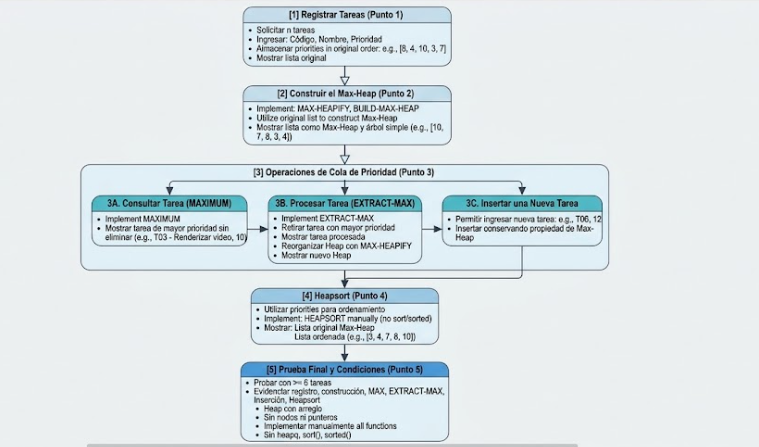

El diagrama de flujo inicia con el registro de tareas, donde se ingresan la cantidad de tareas junto con su código, nombre y prioridad. A continuación, se construye el Max-Heap para organizar los datos de modo que la tarea con mayor prioridad quede siempre en la raíz. Posteriormente, se ejecutan las operaciones de la cola de prioridad, lo que permite consultar la tarea más importante, procesarla y extraerla, o bien insertar una nueva tarea. Luego, se aplica HeapSort para ordenar todas las prioridades de menor a mayor de forma manual utilizando el montículo. Finalmente, el proceso concluye con una prueba final que comprueba el correcto funcionamiento de todo el sistema ejecutándolo con al menos 6 tareas diferentes.

### 5) Análisis de complejidad **[15 pts]**
Incluye:
- Justificación
    - MAX-HEAPIFY ($\mathcal{O}(\log n)$): En el peor de los casos, un elemento desciende desde la raíz hasta una hoja, lo cual toma un tiempo proporcional a la altura del árbol binario completo ($\lfloor \log_2 n \rfloor$).
    - BUILD-MAX-HEAP ($\mathcal{O}(n)$): Aunque se llama a heapify $n/2$ veces, matemáticamente la suma de las alturas de todos los nodos en un árbol completo converge a un límite lineal, resultando en un tiempo óptimo de $\mathcal{O}(n)$.
    - Operaciones de Cola (EXTRACT-MAX e INSERT) ($\mathcal{O}(\log n)$): Deben recorrer como máximo la altura del árbol al reestructurar o flotar elementos.
    - HEAPSORT ($\mathcal{O}(n \log n)$): Realiza $n$ extracciones sucesivas sobre el montículo, y en cada paso el reajuste del heap toma un tiempo logarítmico.
- Función T[n]
    - Construcción del Heap: $T_{\text{build}}(n) = \sum_{h=0}^{\lfloor \log n \rfloor} \frac{n}{2^{h+1}} O(h) = c \cdot n = \mathcal{O}(n)$
    - Operaciones individuales (Heapify / Extract / Insert): $T_{\text{op}}(n) = c_1 \cdot \log n + c_2$
    - Ordenamiento completo (HeapSort): $T_{\text{sort}}(n) = T_{\text{build}}(n) + \sum_{i=1}^{n-1} c \cdot \log i = n \log n + n = \mathcal{O}(n \log n)$
- Mejor y peor caso con gráfica


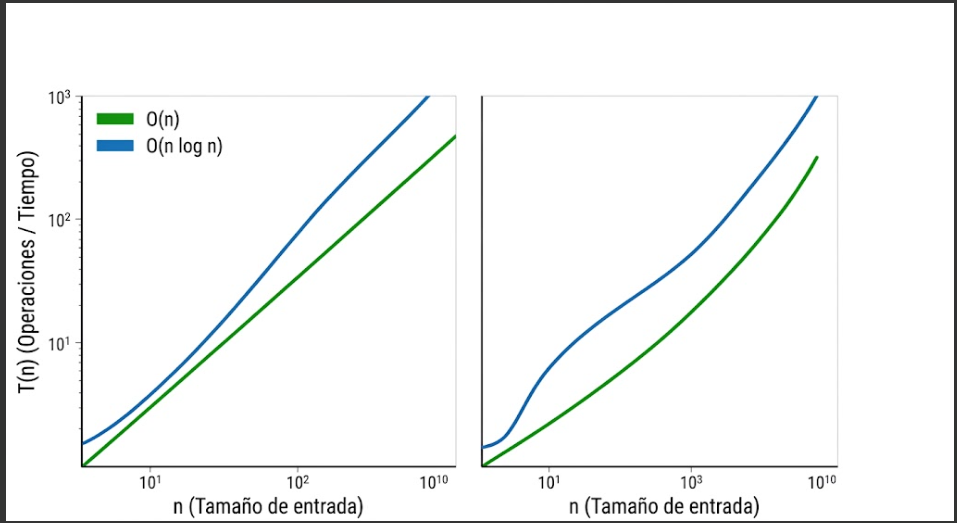

## 6) Código funcional **[15 pts]**



In [2]:
# Laboratorio: Colas de prioridad con Max-Heap (Entrada interactiva)

class TaskItem:
    def __init__(self, code, name, priority):
        self.code = code
        self.name = name
        self.priority = priority

    def __str__(self):
        return f"{self.code} -> {self.name} (Prioridad: {self.priority})"


def _hundir(vector, n, i):
    mayor = i
    izq = 2 * i + 1
    der = 2 * i + 2

    if izq < n and vector[izq].priority > vector[mayor].priority:
        mayor = izq
    if der < n and vector[der].priority > vector[mayor].priority:
        mayor = der

    if mayor != i:
        vector[i], vector[mayor] = vector[mayor], vector[i]
        _hundir(vector, n, mayor)


def construir_heap(vector):
    n = len(vector)
    idx = (n // 2) - 1
    while idx >= 0:
        _hundir(vector, n, idx)
        idx -= 1


def consultar_max(vector):
    if len(vector) == 0:
        return None
    return vector[0]


def extraer_max(vector):
    if len(vector) == 0:
        return None
    tope = vector[0]
    vector[0] = vector[-1]
    vector.pop()
    if len(vector) > 0:
        _hundir(vector, len(vector), 0)
    return tope


def insertar_elemento(vector, nuevo_item):
    vector.append(nuevo_item)
    actual = len(vector) - 1
    while actual > 0:
        padre = (actual - 1) // 2
        if vector[padre].priority < vector[actual].priority:
            vector[padre], vector[actual] = vector[actual], vector[padre]
            actual = padre
        else:
            break


def heapsort_manual(lista_tareas):
    datos = [t.priority for t in lista_tareas]
    tam = len(datos)

    def heapify_local(arr, size, k):
        m = k
        l = 2 * k + 1
        r = 2 * k + 2
        if l < size and arr[l] > arr[m]:
            m = l
        if r < size and arr[r] > arr[m]:
            m = r
        if m != k:
            arr[k], arr[m] = arr[m], arr[k]
            heapify_local(arr, size, m)

    i = tam // 2 - 1
    while i >= 0:
        heapify_local(datos, tam, i)
        i -= 1

    j = tam - 1
    while j > 0:
        datos[0], datos[j] = datos[j], datos[0]
        heapify_local(datos, j, 0)
        j -= 1

    return datos


print_arbol = lambda h: print(f"       [{h[0].priority}]\n      /     \\\n    [{h[1].priority}]     [{h[2].priority}]") if len(h) > 2 else None


# ==========================================
# EJECUCIÓN E INTERACCIÓN (PUNTO 1 AL 5)
# ==========================================
if __name__ == "__main__":
    print("=== 1. REGISTRO DE TAREAS ===")

    # Captura interactiva solicitada por el laboratorio
    n_tareas = int(input("¿Cuántas tareas deseas registrar? (mínimo 6 recomendado): "))
    mis_tareas = []

    for i in range(n_tareas):
        print(f"\n--- Datos de la tarea {i+1} ---")
        c = input("Ingrese el código (ej. T01): ")
        nom = input("Ingrese el nombre de la tarea: ")
        prio = int(input("Ingrese la prioridad numérica: "))
        mis_tareas.append(TaskItem(c, nom, prio))

    print("\nOriginales (prioridades):", [t.priority for t in mis_tareas])

    print("\n=== 2. BUILD MAX-HEAP ===")
    construir_heap(mis_tareas)
    print("Heap resultante:", [t.priority for t in mis_tareas])
    print_arbol(mis_tareas)

    print("\n=== 3A. MAXIMUM ===")
    maximo_actual = consultar_max(mis_tareas)
    print("Tarea con mayor prioridad:", maximo_actual)

    print("\n=== 3B. EXTRACT-MAX ===")
    if len(mis_tareas) > 0:
        sacada = extraer_max(mis_tareas)
        print("Atendida y extraída:", sacada)
        print("Heap tras extracción:", [t.priority for t in mis_tareas])

    print("\n=== 3C. INSERTAR NUEVA TAREA ===")
    print("Ingresa una nueva tarea para probar la inserción:")
    nc = input("Código nueva tarea: ")
    nnom = input("Nombre nueva tarea: ")
    nprio = int(input("Prioridad nueva tarea: "))
    nueva = TaskItem(nc, nnom, nprio)

    insertar_elemento(mis_tareas, nueva)
    print("Heap tras la inserción:", [t.priority for t in mis_tareas])

    print("\n=== 4. HEAPSORT MANUAL ===")
    ordenado = heapsort_manual(mis_tareas)
    print("Lista ordenada de menor a mayor:", ordenado)

=== 1. REGISTRO DE TAREAS ===
¿Cuántas tareas deseas registrar? (mínimo 6 recomendado): 7

--- Datos de la tarea 1 ---
Ingrese el código (ej. T01): T01
Ingrese el nombre de la tarea: hola
Ingrese la prioridad numérica: 32

--- Datos de la tarea 2 ---
Ingrese el código (ej. T01): T02
Ingrese el nombre de la tarea: holaa
Ingrese la prioridad numérica: 33

--- Datos de la tarea 3 ---
Ingrese el código (ej. T01): T03
Ingrese el nombre de la tarea: holaaa
Ingrese la prioridad numérica: 34

--- Datos de la tarea 4 ---
Ingrese el código (ej. T01): T04
Ingrese el nombre de la tarea: holaaaa
Ingrese la prioridad numérica: 35

--- Datos de la tarea 5 ---
Ingrese el código (ej. T01): T05
Ingrese el nombre de la tarea: holaaaaa
Ingrese la prioridad numérica: 36

--- Datos de la tarea 6 ---
Ingrese el código (ej. T01): T06
Ingrese el nombre de la tarea: holaaaaaa
Ingrese la prioridad numérica: 37

--- Datos de la tarea 7 ---
Ingrese el código (ej. T01): T07
Ingrese el nombre de la tarea: holaaaaaaa

## 7) Tests aplicados **[15 pts]**

In [3]:


print("=== INICIANDO PRUEBAS DE VALIDACIÓN (PUNTO 5) ===")

assert len(mis_tareas) > 0, "El arreglo de tareas no puede estar vacío"
print(f"1. Total de tareas activas en el sistema: {len(mis_tareas)}")

if len(mis_tareas) >= 3:
    izq_idx = 2 * 0 + 1
    der_idx = 2 * 0 + 2
    if izq_idx < len(mis_tareas):
        assert mis_tareas[0].priority >= mis_tareas[izq_idx].priority, "Error: La raíz es menor que el hijo izquierdo"
    if der_idx < len(mis_tareas):
        assert mis_tareas[0].priority >= mis_tareas[der_idx].priority, "Error: La raíz es menor que el hijo derecho"
    print("2. Validación de la propiedad Max-Heap estructural: ¡Exitosa!")

copia_prueba = list(mis_tareas)
resultado_sort = heapsort_manual(copia_prueba)

for i in range(len(resultado_sort) - 1):
    assert resultado_sort[i] <= resultado_sort[i+1], "Error: El HeapSort no ordenó correctamente"
print(f"3. Validación de HeapSort (ascendente): {resultado_sort} -> ¡Correcto!")

print("\n¡Todas las pruebas y assertions pasaron sin problemas!")


=== INICIANDO PRUEBAS DE VALIDACIÓN (PUNTO 5) ===
1. Total de tareas activas en el sistema: 7
2. Validación de la propiedad Max-Heap estructural: ¡Exitosa!
3. Validación de HeapSort (ascendente): [32, 33, 34, 35, 36, 37, 38] -> ¡Correcto!

¡Todas las pruebas y assertions del Punto 5 pasaron sin problemas!
